# Probabilistic Forecasts and Reinforcement Learning for Inventory Decisions

This notebook extends `inventory_forecast_optimization.ipynb` with two questions:

1. **Does a probabilistic deep-learning forecast make better inventory decisions?** A PyTorch network forecasts a full negative-binomial demand distribution for every store-item-day. Its quantiles set order-up-to levels directly, instead of a point forecast plus a fixed safety-stock rule.
2. **Can reinforcement learning improve the ordering policy itself?** A PPO agent, written in PyTorch, learns residual corrections to a forecast-driven policy in two settings: the base setting from the first notebook, and one where every order has a fixed cost.

Same data, splits, leakage-safe features, and simulator as the first notebook. Every policy is tuned on the validation period only; the test period is used once for reporting.

**Findings (test period, Q1 2017; tables below):**

* Ordering up to a **quantile of the forecast distribution** costs about **5% less** than the classic safety-stock rule when each policy's setting is chosen on validation (neural: −5.3%, 95% CI −5.7% to −4.8%). The safety-stock rule tuned on validation overshoots by 6.2% against its own best setting in hindsight.
* The **neural forecaster needs about 3.5% less stock** than LightGBM for the same fill rate, although its test WAPE is slightly worse (11.95% vs 11.63%). Its prediction intervals are close to nominal coverage.
* With a **fixed cost per order**, the **PPO agent beats a tuned (s, S) policy by 3.5%** (95% CI −3.9% to −3.1%) with a higher fill rate and less stock. Without an order cost, where base-stock is near-optimal, it gains 1.1%.

## 1. Setup

In [1]:
import copy, json, os, subprocess, sys, time, itertools
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

REPO_URL = "https://github.com/oelwakil/inventory-forecast-optimization.git"
def _find_root():
    for p in (Path.cwd(), Path.cwd().parent):
        if (p / "src" / "features.py").exists():
            return p
    return None

ROOT = _find_root()
if ROOT is None and "google.colab" in sys.modules:
    subprocess.run(["git", "clone", REPO_URL], check=True)
    os.chdir(Path(REPO_URL.split("/")[-1].removesuffix(".git")) / "notebooks")
    ROOT = _find_root()
if ROOT is None:
    raise RuntimeError("Could not find the project's src/ folder. Run this notebook from the repository.")
sys.path.insert(0, str(ROOT))

from src.demo_data import make_demo_data
from src.data_prep import make_splits, TRAIN_END, VAL_END, TEST_START, TEST_END
from src.features import FEATURES, CATEGORICAL, build_features, to_wide
from src.metrics import summarize
from src.simulate import simulate_order_up_to, normal_targets
from src.prob_metrics import score, quantile_targets, poisson_alpha
from src.torch_forecast import make_inputs, train_nb, predict_nb, ensemble_predict
from src.rl_env import InventoryEnv, EnvConfig, run_policy, s_S_policy
from src.rl_agent import train_ppo, PPOConfig, make_policy

# ---- Configuration --------------------------------------------------------------------
USE_DEMO = os.environ.get("USE_DEMO", "0") == "1"   # simulated data: smoke test only
DATA_PATH = ROOT / "data" / "train.csv"
LEAD_TIME, REVIEW_PERIOD = 2, 1
HOLDING_COST, LOST_SALE_COST = 1.0, 20.0
ORDER_COST = 100.0        # fixed cost per order in scenario B (relative units)
N_SEEDS = int(os.environ.get("N_SEEDS", 3))          # ensemble members for the neural forecaster
EPOCHS = int(os.environ.get("EPOCHS", 12))
PPO_ITERS_A = int(os.environ.get("PPO_ITERS_A", 150))
PPO_ITERS_B = int(os.environ.get("PPO_ITERS_B", 300))
SEED = 42
torch.set_num_threads(max(1, os.cpu_count() or 1))

OUT_DIR = ROOT / "results" / ("demo/extension" if USE_DEMO else "extension")
OUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLUE, ORANGE, AQUA, GRAY, INK, PURPLE = "#2a78d6", "#eb6834", "#1baf7a", "#8a8985", "#0b0b0b", "#7b5cd6"
T0 = time.time()

## 2. Data and splits

Same design as the first notebook: train to 2016-06-30, validation 2016-07-01 to 2016-12-31, test 2017-01-01 to 2017-03-31. Features for date *t* use sales from *t − 28* or earlier.

In [2]:
if USE_DEMO:
    print("*** USING SIMULATED DEMO DATA: results are not real ***")
    raw = make_demo_data()
elif DATA_PATH.exists():
    raw = pd.read_csv(DATA_PATH, parse_dates=["date"])
else:
    raise FileNotFoundError(f"{DATA_PATH} not found. Download train.csv from the Kaggle 'Store Item Demand "
                            "Forecasting Challenge' (see README), or set USE_DEMO=1 for a smoke test.")

S = make_splits(raw, LEAD_TIME, REVIEW_PERIOD, buffer_days=7)
feat, n_series, P = S.feat, S.n_series, S.protection
y_all = feat["y"].to_numpy()
T_val, T_test = S.y_va.shape[0], S.y_te.shape[0]
print(f"{n_series} series | train rows {len(S.tr_idx):,} | validation days {T_val} | test days {T_test}")

500 series | train rows 579,500 | validation days 184 | test days 90


## 3. Reference model: LightGBM

The LightGBM configuration chosen by the first notebook's validation search is reused as is (from `results/summary.json`), so both notebooks compare against the same model. The train-only fit gives honest validation errors; the train + validation refit forecasts the test period.

In [3]:
summary_path = ROOT / "results" / "summary.json"
if summary_path.exists() and not USE_DEMO:
    cfg = json.loads(summary_path.read_text())["lightgbm"]
else:   # fall back to the published configuration
    cfg = dict(objective="poisson", learning_rate=0.1, bagging_freq=1, verbose=-1, seed=42, num_threads=0,
               num_leaves=127, min_data_in_leaf=100, feature_fraction=0.7, bagging_fraction=0.9, lambda_l2=1.0,
               rounds_validation=518, rounds_final=570)
lgb_params = {k: v for k, v in cfg.items() if not k.startswith("rounds")}
X = feat[FEATURES]

def fit_lgb(idx, rounds):
    return lgb.train(lgb_params, lgb.Dataset(X.iloc[idx], y_all[idx], categorical_feature=CATEGORICAL),
                     num_boost_round=rounds)

lgb_tr = fit_lgb(S.tr_idx, cfg["rounds_validation"])
lgb_va = np.clip(lgb_tr.predict(X.iloc[S.va_idx]), 0, None).reshape(-1, n_series)
lgb_final = fit_lgb(S.trva_idx, cfg["rounds_final"])
lgb_te = np.clip(lgb_final.predict(X.iloc[S.te_buf_idx]), 0, None).reshape(-1, n_series)
print("LightGBM test:", {k: round(v, 4) for k, v in summarize(S.y_te, lgb_te[:T_test]).items()})

LightGBM test: {'WAPE': 0.1163, 'MAE': 5.329, 'RMSE': 6.9072, 'Bias': 0.0075}


## 4. The PyTorch forecaster

`src/torch_forecast.py` defines one global network for all 500 series:

* **Inputs:** the same leakage-safe features. Lag and rolling counts enter as ratios to the series level; store, item, weekday and month enter through learned embeddings; day-of-year and day-of-month as sine/cosine pairs.
* **Output:** a negative-binomial distribution per store-item-day, mean `μ = level × exp(f(x))` and variance `μ + α μ²`.
* **Loss:** negative-binomial negative log-likelihood, so the network is rewarded for an honest spread as well as an accurate mean.
* **Training:** AdamW with a one-cycle schedule, 12 epochs, best epoch by validation likelihood; an ensemble of 3 seeds combined as a mixture.

### 4a. Design choice made on a backtest, not on the test period

The level the network forecasts relative to is a design choice: the last 91 days (reacts fast, but carries last quarter's seasonal level) or the last 365 days (free of seasonality). Because the test period is a first quarter, the choice is made on a **Q1-2016 backtest**: train on data to 2015-12-31, forecast January to March 2016. No 2017 data is used.

In [4]:
dates = pd.DatetimeIndex(feat["date"])
usable = feat["roll_mean_91"].notna().to_numpy()
bt_tr = np.nonzero(usable & (dates <= "2015-12-31"))[0]
bt_te = np.nonzero((dates >= "2016-01-01") & (dates <= "2016-03-31"))[0]
y_bt = y_all[bt_te].reshape(-1, n_series)
bt_rows = {}
m = fit_lgb(bt_tr, cfg["rounds_validation"])
bt_rows["LightGBM"] = summarize(y_bt, np.clip(m.predict(X.iloc[bt_te]), 0, None).reshape(-1, n_series))
for anchor in ["roll_mean_91", "roll_mean_365"]:
    net, _ = train_nb(make_inputs(feat.iloc[bt_tr], anchor), y_all[bt_tr], epochs=EPOCHS, seed=0)
    mu, _ = predict_nb(net, make_inputs(feat.iloc[bt_te], anchor))
    bt_rows[f"Neural, level = {anchor.replace('roll_mean_', '')}-day mean"] = summarize(y_bt, mu.reshape(-1, n_series))
backtest = pd.DataFrame(bt_rows).T
ANCHOR = "roll_mean_365" if backtest.loc["Neural, level = 365-day mean", "WAPE"] <= backtest.loc["Neural, level = 91-day mean", "WAPE"] else "roll_mean_91"
print("chosen level:", ANCHOR)
backtest.round(4)

chosen level: roll_mean_365


,WAPE,MAE,RMSE,Bias
LightGBM,0.1208,5.3318,6.9705,-0.0269
"Neural, level = 91-day mean",0.1173,5.1768,6.6958,0.0057
"Neural, level = 365-day mean",0.1171,5.1704,6.6890,0.0042


### 4b. Train the ensemble

seed 0: best epoch 12, validation NLL 3.3920, 80s


seed 1: best epoch 12, validation NLL 3.3917, 81s


seed 2: best epoch 11, validation NLL 3.3924, 78s


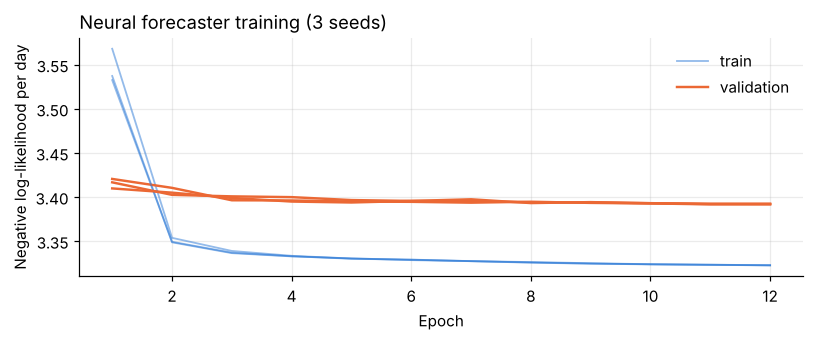

In [5]:
inp = lambda idx: make_inputs(feat.iloc[idx], ANCHOR)
inp_tr, inp_va, inp_trva, inp_te = inp(S.tr_idx), inp(S.va_idx), inp(S.trva_idx), inp(S.te_buf_idx)
models_tr, logs = [], []
for s in range(N_SEEDS):
    net, log = train_nb(inp_tr, y_all[S.tr_idx], inp_va, y_all[S.va_idx], epochs=EPOCHS, seed=s)
    models_tr.append(net); logs.append(log)
    print(f"seed {s}: best epoch {log.best_epoch}, validation NLL {min(log.val_nll):.4f}, {log.seconds:.0f}s")
mu_va, a_va = (v.reshape(-1, n_series) for v in ensemble_predict(models_tr, inp_va))

models_final = []
for s in range(N_SEEDS):   # refit on train + validation for the test forecast, same number of epochs
    net, log = train_nb(inp_trva, y_all[S.trva_idx], epochs=EPOCHS, seed=s)
    models_final.append(net)
mu_te, a_te = (v.reshape(-1, n_series) for v in ensemble_predict(models_final, inp_te))

fig, ax = plt.subplots(figsize=(7.5, 3.2))
for i, log in enumerate(logs):
    ax.plot(log.epochs, log.train_nll, color=BLUE, alpha=0.5, lw=1.2, label="train" if i == 0 else None)
    ax.plot(log.epochs, log.val_nll, color=ORANGE, lw=1.6, label="validation" if i == 0 else None)
ax.set_xlabel("Epoch"); ax.set_ylabel("Negative log-likelihood per day")
ax.set_title("Neural forecaster training (3 seeds)", loc="left"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(OUT_DIR / "training_curves.png", bbox_inches="tight"); plt.show()

### 4c. Point accuracy

The mean of each forecast distribution, scored like the first notebook.

In [6]:
acc = pd.DataFrame({
    "LightGBM (validation)": summarize(S.y_va, lgb_va), "Neural (validation)": summarize(S.y_va, mu_va),
    "LightGBM (test)": summarize(S.y_te, lgb_te[:T_test]), "Neural (test)": summarize(S.y_te, mu_te[:T_test]),
}).T
acc.round(4)

,WAPE,MAE,RMSE,Bias
LightGBM (validation),0.1035,6.1150,7.9723,-0.0120
Neural (validation),0.1010,5.9658,7.7271,0.0004
LightGBM (test),0.1163,5.3290,6.9072,0.0075
Neural (test),0.1195,5.4761,7.0624,0.0398


## 5. Is the forecast uncertainty honest?

Three predictive distributions are scored on the test period:

* **LightGBM + normal:** the point forecast with each series' validation error spread. This is the distribution implied by the classic safety-stock rule.
* **LightGBM + Poisson:** the point forecast with Poisson noise around it.
* **Neural negative binomial:** the network's own distribution.

**CRPS** (continuous ranked probability score) measures the whole distribution, in units of demand; lower is better, and for a point forecast it equals the MAE. **Coverage** is the share of outcomes inside the central 50/80/90/95% prediction intervals; a calibrated forecast matches the nominal level.

In [7]:
y_flat = S.y_te
sig_lgb = np.sqrt(np.mean((S.y_va - lgb_va) ** 2, axis=0))
sig_nn = np.sqrt(np.mean((S.y_va - mu_va) ** 2, axis=0))
dists = {
    "LightGBM + normal": ("normal", lgb_te[:T_test], np.tile(sig_lgb, (T_test, 1))),
    "LightGBM + Poisson": ("nb", lgb_te[:T_test], poisson_alpha(lgb_te[:T_test])),
    "Neural negative binomial": ("nb", mu_te[:T_test], a_te[:T_test]),
}
prob, pits = {}, {}
for name, (kind, a, b) in dists.items():
    r = score(y_flat, kind, a, b)
    pits[name] = r.pop("pit")
    prob[name] = r
prob = pd.DataFrame(prob).T
prob.round(4)

,CRPS,50% interval,80% interval,90% interval,95% interval
LightGBM + normal,3.8012,0.5618,0.8574,0.9380,0.9714
LightGBM + Poisson,3.7654,0.4942,0.7936,0.8936,0.9444
Neural negative binomial,3.8427,0.4964,0.7971,0.8978,0.9472


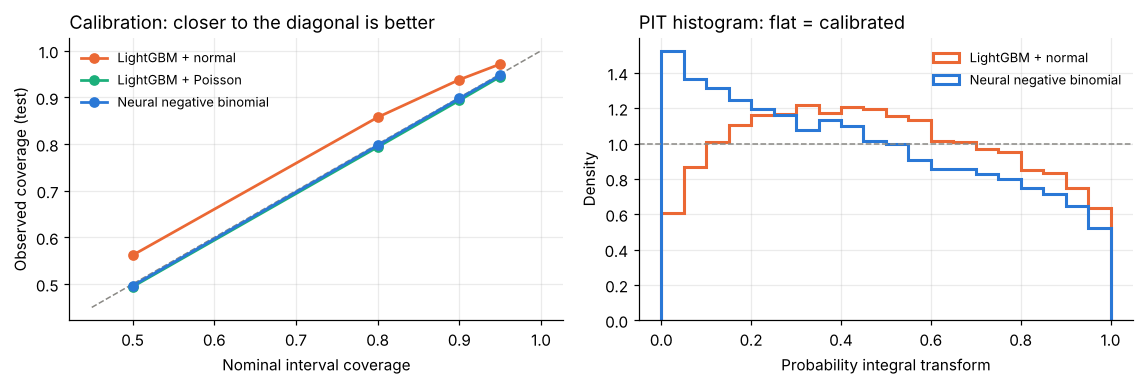

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
levels = np.array([0.5, 0.8, 0.9, 0.95])
colors = {"LightGBM + normal": ORANGE, "LightGBM + Poisson": AQUA, "Neural negative binomial": BLUE}
ax = axes[0]
ax.plot([0.45, 1], [0.45, 1], color=GRAY, ls="--", lw=1)
for name in dists:
    ax.plot(levels, prob.loc[name, [f"{int(l*100)}% interval" for l in levels]], marker="o", color=colors[name], lw=1.8, label=name)
ax.set_xlabel("Nominal interval coverage"); ax.set_ylabel("Observed coverage (test)")
ax.set_title("Calibration: closer to the diagonal is better", loc="left"); ax.legend(frameon=False, fontsize=8.5)
ax = axes[1]
bins = np.linspace(0, 1, 21)
for name in ["LightGBM + normal", "Neural negative binomial"]:
    ax.hist(pits[name], bins=bins, density=True, histtype="step", lw=2, color=colors[name], label=name)
ax.axhline(1, color=GRAY, ls="--", lw=1)
ax.set_xlabel("Probability integral transform"); ax.set_ylabel("Density")
ax.set_title("PIT histogram: flat = calibrated", loc="left"); ax.legend(frameon=False, fontsize=8.5)
fig.tight_layout(); fig.savefig(OUT_DIR / "calibration.png", bbox_inches="tight"); plt.show()

## 6. From forecast distributions to inventory decisions

Every method feeds the same simulator (daily review, 2-day lead time, lost sales):

* **Safety-stock rule** (normal): order up to forecast over the protection period + `z × σ × √2`, σ from validation errors.
* **Quantile rule**: order up to the *q*-quantile of protection-period demand from the forecast distribution, so safety stock follows the forecast's own uncertainty day by day.

Two comparisons:

1. **Inventory at equal service:** sweep *z* or *q* on the test period and read the stock needed for 95/98/99% fill. This compares forecasts without any tuning choice.
2. **Cost when tuned on validation:** choose *z* or *q* by lowest simulated cost on the validation period, then apply it to the test period. This is what a planner could actually deploy. Confidence intervals come from resampling the 500 series (bootstrap).

In [9]:
T_v = T_val - P   # last validation days need forecasts beyond the window
methods = {
    "LightGBM + safety-stock rule": ("z", lambda f, a, T, g: normal_targets(f, sig_lgb, g, T, P), lgb_va, None, lgb_te, None),
    "Neural + safety-stock rule": ("z", lambda f, a, T, g: normal_targets(f, sig_nn, g, T, P), mu_va, None, mu_te, None),
    "LightGBM + Poisson quantile": ("q", lambda f, a, T, g: quantile_targets(f, poisson_alpha(f), g, T, P), lgb_va, None, lgb_te, None),
    "Neural + NB quantile": ("q", lambda f, a, T, g: quantile_targets(f, a, g, T, P), mu_va, a_va, mu_te, a_te),
}
z_grid = np.round(np.arange(-0.5, 3.21, 0.05), 2)
q_grid = np.round(np.concatenate([np.arange(0.30, 0.95, 0.025), np.arange(0.95, 0.9991, 0.002)]), 4)
sim = {}
for name, (kind, fn, fv, av, ft, at) in methods.items():
    grid = z_grid if kind == "z" else q_grid
    val_cost = np.array([simulate_order_up_to(S.y_va[:T_v], fn(fv, av, T_v, g), LEAD_TIME)["total_cost"] for g in grid])
    test = [simulate_order_up_to(S.y_te, fn(ft, at, T_test, g), LEAD_TIME) for g in grid]
    sim[name] = {"kind": kind, "grid": grid, "val_cost": val_cost, "test": test}
perfect = simulate_order_up_to(S.y_te, normal_targets(S.wide.loc[TEST_START:].to_numpy()[: T_test + P], np.zeros(n_series), 0, T_test, P), LEAD_TIME)
print(f"simulations done ({time.time() - T0:.0f}s elapsed)")

simulations done (752s elapsed)


In [10]:
def frontier(name, cols=None):
    t = sim[name]["test"]
    cols = np.arange(n_series) if cols is None else cols
    sold = np.array([r["per_series_sold"][cols].sum() for r in t])
    lost = np.array([r["per_series_lost"][cols].sum() for r in t])
    oh = np.array([r["per_series_on_hand"][cols].mean() for r in t])
    fill = sold / (sold + lost)
    o = np.argsort(fill)
    return fill[o], oh[o]

targets = [0.95, 0.98, 0.99]
need = pd.DataFrame({name: [np.interp(t, *frontier(name)) for t in targets] for name in sim},
                    index=[f"on-hand @ {t:.0%} fill" for t in targets]).T

# bootstrap over series: inventory needed at 98% fill relative to LightGBM + safety-stock rule
rng = np.random.default_rng(SEED)
boot = {name: [] for name in sim}
for _ in range(400):
    cols = rng.integers(0, n_series, n_series)
    ref = np.interp(0.98, *frontier("LightGBM + safety-stock rule", cols))
    for name in sim:
        boot[name].append((np.interp(0.98, *frontier(name, cols)) / ref - 1) * 100)
need["vs LightGBM rule @98% (%)"] = [np.mean(boot[n]) for n in sim]
need["95% CI"] = [f"[{np.percentile(boot[n], 2.5):.1f}, {np.percentile(boot[n], 97.5):.1f}]" for n in sim]
print("Average on-hand inventory needed (units per store-item per day), test period")
need.round(2)

Average on-hand inventory needed (units per store-item per day), test period


,on-hand @ 95% fill,on-hand @ 98% fill,on-hand @ 99% fill,vs LightGBM rule @98% (%),95% CI
LightGBM + safety-stock rule,4.96,9.19,12.50,0.00,"[0.0, 0.0]"
Neural + safety-stock rule,4.77,8.87,12.10,-3.43,"[-3.9, -3.0]"
LightGBM + Poisson quantile,4.96,9.15,12.43,-0.35,"[-0.5, -0.2]"
Neural + NB quantile,4.78,8.86,12.06,-3.49,"[-4.0, -3.0]"


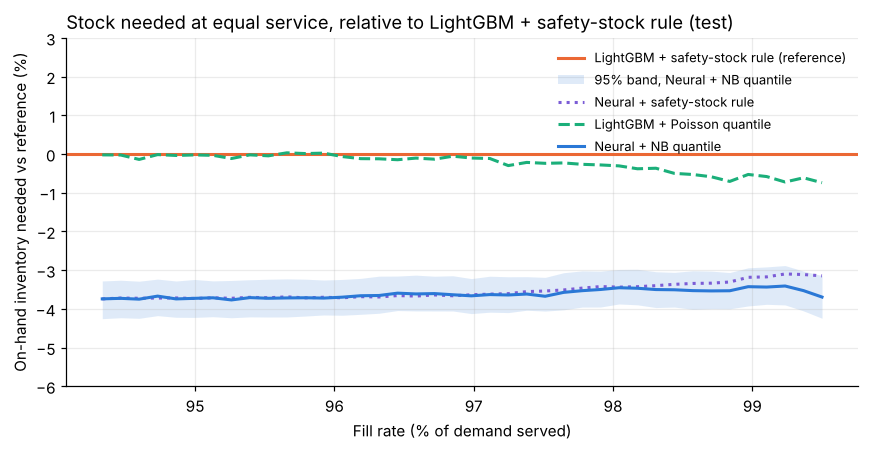

In [11]:
fstyle = {"LightGBM + safety-stock rule": (ORANGE, "-"), "Neural + safety-stock rule": (PURPLE, ":"),
          "LightGBM + Poisson quantile": (AQUA, "--"), "Neural + NB quantile": (BLUE, "-")}
lo = max(frontier(n)[0].min() for n in sim) + 0.002   # only where every policy has data
fill_axis = np.linspace(max(lo, 0.93), 0.995, 40)
ref_curve = np.interp(fill_axis, *frontier("LightGBM + safety-stock rule"))
band = []
for _ in range(200):   # bootstrap band for the neural quantile policy
    cols = rng.integers(0, n_series, n_series)
    band.append(np.interp(fill_axis, *frontier("Neural + NB quantile", cols)) /
                np.interp(fill_axis, *frontier("LightGBM + safety-stock rule", cols)) * 100 - 100)
band = np.percentile(band, [2.5, 97.5], axis=0)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.axhline(0, color=ORANGE, lw=2, label="LightGBM + safety-stock rule (reference)")
ax.fill_between(fill_axis * 100, band[0], band[1], color=BLUE, alpha=0.15, lw=0, label="95% band, Neural + NB quantile")
for name in ["Neural + safety-stock rule", "LightGBM + Poisson quantile", "Neural + NB quantile"]:
    c, ls = fstyle[name]
    ax.plot(fill_axis * 100, np.interp(fill_axis, *frontier(name)) / ref_curve * 100 - 100, color=c, ls=ls, lw=2, label=name)
ax.set_xlabel("Fill rate (% of demand served)")
ax.set_ylabel("On-hand inventory needed vs reference (%)")
ax.set_title("Stock needed at equal service, relative to LightGBM + safety-stock rule (test)", loc="left")
ax.legend(frameon=False, fontsize=8.5, loc="upper right")
ax.set_ylim(-6, 3)
fig.tight_layout(); fig.savefig(OUT_DIR / "frontier_probabilistic.png", bbox_inches="tight"); plt.show()

In [12]:
rows, ps = [], {}
for name, s in sim.items():
    iv = int(np.argmin(s["val_cost"]))
    test_cost = np.array([r["total_cost"] for r in s["test"]])
    ih = int(np.argmin(test_cost))
    r = s["test"][iv]
    ps[name] = r["per_series_cost"]
    rows.append({"method": name, "tuned on validation": f"{s['kind']} = {s['grid'][iv]:g}",
                 "test cost": r["total_cost"], "fill rate": r["fill_rate"], "avg on-hand": r["avg_on_hand"],
                 "best in hindsight": f"{s['kind']} = {s['grid'][ih]:g}", "hindsight cost": test_cost[ih],
                 "tuning gap (%)": (r["total_cost"] / test_cost[ih] - 1) * 100})
deploy = pd.DataFrame(rows).set_index("method")
base_ps = ps["LightGBM + safety-stock rule"]
idx = rng.integers(0, n_series, (5000, n_series))
for name in sim:
    rel = (ps[name][idx].sum(1) / base_ps[idx].sum(1) - 1) * 100
    deploy.loc[name, "vs LightGBM rule (%)"] = (ps[name].sum() / base_ps.sum() - 1) * 100
    deploy.loc[name, "95% CI"] = f"[{np.percentile(rel, 2.5):.1f}, {np.percentile(rel, 97.5):.1f}]"
    deploy.loc[name, "series cheaper"] = f"{np.mean(ps[name] < base_ps):.0%}"
print("Test-period cost with the setting chosen on validation (relative units)")
deploy.round(4)

Test-period cost with the setting chosen on validation (relative units)


,tuned on validation,test cost,fill rate,avg on-hand,best in hindsight,hindsight cost,tuning gap (%),vs LightGBM rule (%),95% CI,series cheaper
method,,,,,,,,,,
LightGBM + safety-stock rule,z = 1.7,971606.2908,0.9980,19.7437,z = 1.3,914535.4617,6.2404,0.0000,"[0.0, 0.0]",0%
Neural + safety-stock rule,z = 1.6,997423.2605,0.9988,21.0535,z = 1.05,892115.5228,11.8043,2.6571,"[2.2, 3.2]",31%
LightGBM + Poisson quantile,q = 0.958,921967.0000,0.9970,17.7210,q = 0.925,908392.0000,1.4944,-5.1090,"[-5.5, -4.7]",88%
Neural + NB quantile,q = 0.925,920462.0000,0.9977,18.3254,q = 0.875,887116.0000,3.7589,-5.2639,"[-5.7, -4.8]",86%


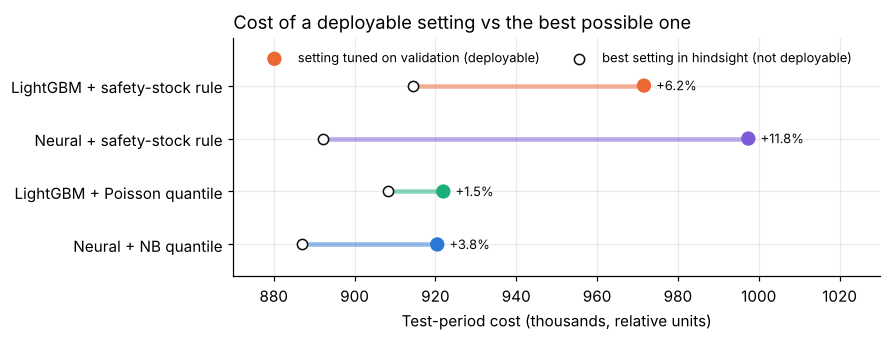

In [13]:
fig, ax = plt.subplots(figsize=(8.2, 3.2))
names = list(sim)
y = np.arange(len(names))
for i, n in enumerate(names):
    ax.plot([deploy.loc[n, "hindsight cost"] / 1e3, deploy.loc[n, "test cost"] / 1e3], [i, i], color=fstyle[n][0], lw=3, alpha=0.5)
ax.scatter(deploy["test cost"] / 1e3, y, color=[fstyle[n][0] for n in names], s=70, zorder=3, label="setting tuned on validation (deployable)")
ax.scatter(deploy["hindsight cost"] / 1e3, y, facecolor="white", edgecolor=INK, s=45, zorder=4, label="best setting in hindsight (not deployable)")
for i, n in enumerate(names):
    ax.annotate(f"+{deploy.loc[n, 'tuning gap (%)']:.1f}%", (deploy.loc[n, "test cost"] / 1e3, i), xytext=(8, -3), textcoords="offset points", fontsize=8.5, color=INK)
ax.set_yticks(y, names); ax.invert_yaxis(); ax.set_ylim(len(names) - 0.4, -0.9)
ax.set_xlabel("Test-period cost (thousands, relative units)")
ax.set_title("Cost of a deployable setting vs the best possible one", loc="left")
ax.legend(frameon=False, loc="upper center", fontsize=8.5, ncol=2, bbox_to_anchor=(0.5, 1.0))
ax.set_xlim(870, 1030)
fig.tight_layout(); fig.savefig(OUT_DIR / "deployable_cost.png", bbox_inches="tight"); plt.show()

## 7. Reinforcement learning for the ordering decision

`src/rl_env.py` wraps the same lost-sales dynamics as a vectorised environment over all 500 series; a unit test checks that it reproduces the simulator exactly. The agent observes on-hand stock, the order pipeline, the neural forecast for the next days, the protection-period mean and spread, and tomorrow's weekday.

`src/rl_agent.py` trains one shared actor-critic network with **PPO** (clipped objective, generalised advantage estimation, time-limit bootstrapping). The agent learns a **residual**: its action is added to a forecast-driven base policy, and an untrained agent reproduces that base policy exactly. This keeps learning stable and makes the comparison clean: any gain is what RL adds on top of a well-tuned heuristic.

Training uses the **validation period** (neural forecasts from the train-only ensemble), in 42-day episodes starting at random days. The checkpoint with the lowest cost over the validation window is kept. The test period is never seen in training.

In [14]:
dow_va = pd.date_range(pd.Timestamp(TRAIN_END) + pd.Timedelta(days=1), periods=mu_va.shape[0]).dayofweek.to_numpy()
dow_te = pd.date_range(TEST_START, periods=mu_te.shape[0]).dayofweek.to_numpy()
T_rl = T_val - (LEAD_TIME + 2)

def make_env(split, cfg, z0=0.0, unit="sd"):
    if split == "val":
        e = InventoryEnv(S.y_va[:T_rl], mu_va, a_va, cfg, z0, unit); e.dow = dow_va
    else:
        e = InventoryEnv(S.y_te, mu_te, a_te, cfg, z0, unit); e.dow = dow_te
    return e

def fmt(r):
    return {"test cost": r["total_cost"], "fill rate": r["fill_rate"], "avg on-hand": r["avg_on_hand"],
            "orders per series-day": r["orders_per_series_day"]}
zero = lambda o: np.zeros(len(o))

### 7a. Scenario A: the base setting

No fixed order cost. Theory says a well-tuned base-stock policy is close to optimal here (short lead time, high lost-sale penalty), so this scenario is mainly a check: RL should find little to improve, and must not find gains that come from exploiting the simulator.

In [15]:
cfgA = EnvConfig(lead_time=LEAD_TIME, holding_cost=HOLDING_COST, lost_sale_cost=LOST_SALE_COST)
zA_grid = np.round(np.arange(-0.5, 3.01, 0.1), 2)
zA_val = {z: run_policy(make_env("val", cfgA, z), zero)["total_cost"] for z in zA_grid}
zA = min(zA_val, key=zA_val.get)
zA_test = {z: run_policy(make_env("test", cfgA, z), zero) for z in zA_grid}
zA_hind = min(zA_test, key=lambda z: zA_test[z]["total_cost"])
netA, logA = train_ppo(make_env("val", cfgA, zA), PPOConfig(iterations=PPO_ITERS_A, seed=SEED))
rlA = run_policy(make_env("test", cfgA, zA), make_policy(netA))
scenA = pd.DataFrame({
    f"Base-stock, z = {zA:g} (tuned on validation)": fmt(zA_test[zA]),
    "RL residual on base-stock": fmt(rlA),
    f"Base-stock, z = {zA_hind:g} (best in hindsight)": fmt(zA_test[zA_hind]),
}).T
print(f"PPO: {logA.seconds:.0f}s, best checkpoint at iteration {logA.best_iteration}")
scenA.round(4)

PPO: 47s, best checkpoint at iteration 120


,test cost,fill rate,avg on-hand,orders per series-day
"Base-stock, z = 1.6 (tuned on validation)",951874.5516,0.9983,19.6333,1.0
RL residual on base-stock,941162.0053,0.9982,19.2565,1.0
"Base-stock, z = 1.1 (best in hindsight)",887777.6659,0.9949,15.0974,1.0


### 7b. Scenario B: a fixed cost per order

Each order now costs 100 (relative units) regardless of size, as with a truck dispatch or a purchase-order handling cost. Ordering every day is wasteful; a good policy batches orders. The benchmark is a properly tuned **forecast-driven (s, S) policy**: reorder only when the inventory position falls below `s = m + z·sd` of protection-period demand, then order up to `s` plus a number of days of cover. Both parameters are tuned on validation by grid search. The RL agent learns a residual on top of that tuned (s, S) policy: when to order earlier or later, and how much more or less.

In [16]:
cfgB = EnvConfig(lead_time=LEAD_TIME, holding_cost=HOLDING_COST, lost_sale_cost=LOST_SALE_COST, order_cost=ORDER_COST)
zB_val = {z: run_policy(make_env("val", cfgB, z), zero)["total_cost"] for z in zA_grid}
zB = min(zB_val, key=zB_val.get)
ss_grid = list(itertools.product(np.round(np.arange(-2.5, 3.01, 0.25), 2), np.arange(0, 8.01, 0.5)))
def ss_cost(split, zs, c):
    e = make_env(split, cfgB, 0.0, "scale")
    return run_policy(e, s_S_policy(e, zs, c))
ss_val = {g: ss_cost("val", *g)["total_cost"] for g in ss_grid}
ss_best = min(ss_val, key=ss_val.get)
ss_test = {g: ss_cost("test", *g)["total_cost"] for g in ss_grid}
ss_hind = min(ss_test, key=ss_test.get)
print(f"(s, S) tuned on validation: z_s = {ss_best[0]:g}, cover = {ss_best[1]:g} days; best in hindsight on test: {ss_hind}")

envB = make_env("val", cfgB, 0.0, "scale")
netB, logB = train_ppo(envB, PPOConfig(iterations=PPO_ITERS_B, init_log_std=-1.0, seed=SEED),
                       base_policy=s_S_policy(envB, *ss_best))
eB = make_env("test", cfgB, 0.0, "scale")
rlB = run_policy(eB, make_policy(netB, s_S_policy(eB, *ss_best)))
ssB = ss_cost("test", *ss_best)
scenB = pd.DataFrame({
    f"Daily base-stock, z = {zB:g} (tuned on validation)": fmt(run_policy(make_env("test", cfgB, zB), zero)),
    f"(s, S), tuned on validation": fmt(ssB),
    "RL residual on (s, S)": fmt(rlB),
    f"(s, S), best in hindsight on test": fmt(ss_cost("test", *ss_hind)),
}).T
scenB["vs (s, S) tuned (%)"] = (scenB["test cost"] / ssB["total_cost"] - 1) * 100
print(f"PPO: {logB.seconds:.0f}s, best checkpoint at iteration {logB.best_iteration}")
scenB.round(4)

(s, S) tuned on validation: z_s = -0.5, cover = 1.5 days; best in hindsight on test: (np.float64(-0.75), np.float64(1.5))


PPO: 97s, best checkpoint at iteration 290


,test cost,fill rate,avg on-hand,orders per series-day,"vs (s, S) tuned (%)"
"Daily base-stock, z = 1.6 (tuned on validation)",5.451875e+06,0.9983,19.6333,1.0000,22.5070
"(s, S), tuned on validation",4.450254e+06,0.9944,45.5778,0.4817,0.0000
"RL residual on (s, S)",4.293936e+06,0.9963,44.1089,0.4789,-3.5126
"(s, S), best in hindsight on test",4.442666e+06,0.9921,43.4513,0.4804,-0.1705


In [17]:
# Paired bootstrap over series: RL vs the tuned (s, S) policy on the test period
idx = rng.integers(0, n_series, (5000, n_series))
relB = (rlB["per_series_cost"][idx].sum(1) / ssB["per_series_cost"][idx].sum(1) - 1) * 100
relA = (rlA["per_series_cost"][idx].sum(1) / zA_test[zA]["per_series_cost"][idx].sum(1) - 1) * 100
rl_ci = pd.DataFrame({
    "Scenario A: RL vs base-stock": [(rlA["total_cost"] / zA_test[zA]["total_cost"] - 1) * 100, np.percentile(relA, 2.5), np.percentile(relA, 97.5), np.mean(rlA["per_series_cost"] < zA_test[zA]["per_series_cost"])],
    "Scenario B: RL vs (s, S)": [(rlB["total_cost"] / ssB["total_cost"] - 1) * 100, np.percentile(relB, 2.5), np.percentile(relB, 97.5), np.mean(rlB["per_series_cost"] < ssB["per_series_cost"])],
}, index=["cost change (%)", "95% CI low", "95% CI high", "share of series cheaper"]).T
rl_ci.round(3)

,cost change (%),95% CI low,95% CI high,share of series cheaper
Scenario A: RL vs base-stock,-1.125,-1.196,-1.053,0.886
"Scenario B: RL vs (s, S)",-3.513,-3.880,-3.130,0.774


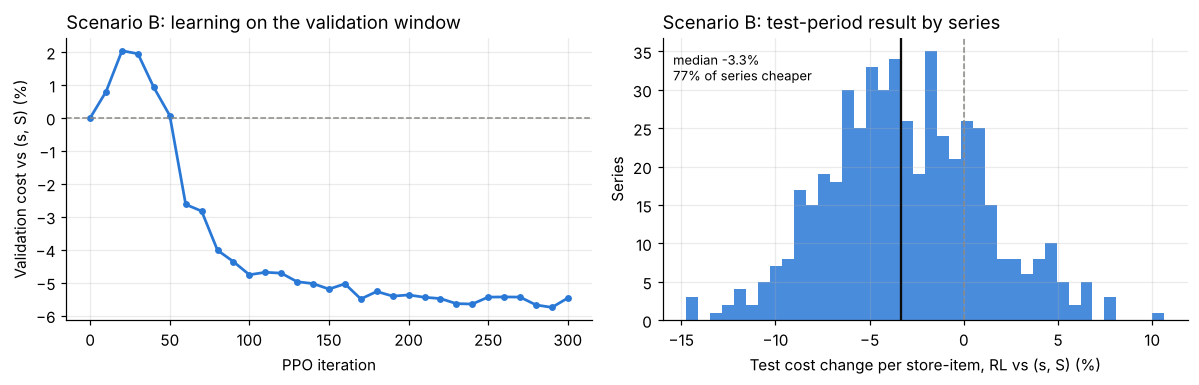

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.plot(logB.eval_iteration, np.array(logB.eval_cost) / logB.eval_cost[0] * 100 - 100, color=BLUE, marker="o", ms=3.5, lw=1.8)
ax.axhline(0, color=GRAY, ls="--", lw=1)
ax.set_xlabel("PPO iteration"); ax.set_ylabel("Validation cost vs (s, S) (%)")
ax.set_title("Scenario B: learning on the validation window", loc="left")

ax = axes[1]
chg = (rlB["per_series_cost"] / ssB["per_series_cost"] - 1) * 100
ax.hist(chg, bins=40, color=BLUE, alpha=0.85)
ax.axvline(0, color=GRAY, ls="--", lw=1)
ax.axvline(np.median(chg), color=INK, lw=1.5)
ax.text(0.02, 0.95, f"median {np.median(chg):.1f}%\n{np.mean(chg < 0):.0%} of series cheaper", transform=ax.transAxes,
        va="top", fontsize=8.5)
ax.set_xlabel("Test cost change per store-item, RL vs (s, S) (%)"); ax.set_ylabel("Series")
ax.set_title("Scenario B: test-period result by series", loc="left")
fig.tight_layout(); fig.savefig(OUT_DIR / "rl_scenario_b.png", bbox_inches="tight"); plt.show()

## 8. Save results

In [19]:
def clean(o):
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o
ext = {
    "data_source": "SIMULATED DEMO DATA" if USE_DEMO else "Kaggle Store Item Demand Forecasting Challenge",
    "config": {"lead_time": LEAD_TIME, "holding_cost": HOLDING_COST, "lost_sale_cost": LOST_SALE_COST,
               "order_cost_scenario_b": ORDER_COST, "n_seeds": N_SEEDS, "epochs": EPOCHS,
               "ppo_iterations": {"A": PPO_ITERS_A, "B": PPO_ITERS_B}, "level_anchor": ANCHOR},
    "backtest_q1_2016": backtest.round(4).to_dict("index"),
    "point_accuracy": acc.round(4).to_dict("index"),
    "probabilistic_test": prob.round(4).to_dict("index"),
    "inventory_needed_test": need.round(3).to_dict("index"),
    "deployable_cost_test": deploy.round(3).to_dict("index"),
    "perfect_foresight_cost": perfect["total_cost"],
    "rl_scenario_a": scenA.round(4).to_dict("index"),
    "rl_scenario_b": {**scenB.round(4).to_dict("index"), "s_S_validation": list(ss_best), "s_S_hindsight": list(ss_hind)},
    "rl_bootstrap": rl_ci.round(3).to_dict("index"),
    "ppo_best_iteration": {"A": logA.best_iteration, "B": logB.best_iteration},
    "runtime_seconds": time.time() - T0,
}
(OUT_DIR / "summary.json").write_text(json.dumps(clean(ext), indent=2))
torch.save({"forecaster": [m.state_dict() for m in models_final], "ppo_A": netA.state_dict(), "ppo_B": netB.state_dict()},
           OUT_DIR / "models.pt")
print(f"saved to {OUT_DIR.resolve()} | total runtime {(time.time() - T0) / 60:.1f} min")

saved to /home/claude/inventory-forecast-optimization/results/extension | total runtime 15.2 min


## 9. Limitations

- **One test quarter.** The test period (Q1 2017) is evaluated once. The Q1-2016 backtest suggests results vary by year: there the neural model beat LightGBM on point accuracy, while in 2017 it did not.
- **Clean data.** Demand is close to Poisson, so the negative-binomial dispersion is small and the gains from modelling spread come mostly from letting safety stock follow the forecast level day by day. Data with promotions, stockouts, and intermittent demand would test the distributional model harder.
- **Independent days.** Protection-period quantiles treat daily demands as independent given the forecast. Correlated errors would make them too narrow.
- **RL scope.** The agent is trained on six months of validation data with forecasts from one model. It learns residuals on top of a heuristic rather than a policy from scratch; that is a design choice for stability, not a limitation of the method. Gains are specific to the assumed costs.
- **Relative costs.** Holding, lost-sale, and order costs are illustrative, not estimated from a retailer.